# Praktikum 1 - JST Sederhana dengan Backpropagation Manual

Praktikum ini membangun jaringan saraf tiruan dua layer dari nol menggunakan NumPy untuk menyelesaikan masalah **XOR**. Proses training memakai **forward pass**, perhitungan error, **backpropagation**, dan **gradient descent**.

Eksperimen yang dilakukan:

1. Baseline: 2 neuron hidden layer dengan aktivasi Sigmoid.
2. Mengubah jumlah neuron hidden layer menjadi 3.
3. Menambahkan fungsi aktivasi ReLU pada hidden layer.

## 1. Dataset XOR

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Dataset XOR
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)

print('X:')
print(X)
print('y:')
print(y)

X:
[[0. 0.]
 [0. 1.]
 [1. 0.]
 [1. 1.]]
y:
[[0.]
 [1.]
 [1.]
 [0.]]


## 2. Fungsi Aktivasi

- **Sigmoid** dipakai pada hidden layer dan output layer.
- **ReLU** dipakai sebagai alternatif pada hidden layer.
- Turunan ReLU dihitung dari nilai **pre-activation** `z`, bukan dari output aktivasi.

In [2]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def sigmoid_derivative(a):
    # a adalah output sigmoid
    return a * (1 - a)


def relu(x):
    return np.maximum(0, x)


def relu_derivative(z):
    # z adalah nilai sebelum aktivasi
    return (z > 0).astype(float)

## 3. Inisialisasi Bobot

Bobot diinisialisasi dengan `numpy.random.default_rng(seed)` agar setiap eksperimen dapat direproduksi.

In [3]:
def init_weights(input_size, hidden_size, output_size, seed=42):
    rng = np.random.default_rng(seed)
    W1 = rng.normal(size=(input_size, hidden_size))
    b1 = np.zeros((1, hidden_size))
    W2 = rng.normal(size=(hidden_size, output_size))
    b2 = np.zeros((1, output_size))
    return W1, b1, W2, b2

## 4. Training dengan Backpropagation

Fungsi `train_xor` menjalankan forward pass, menghitung MSE, melakukan backpropagation, lalu memperbarui bobot dengan gradient descent.

In [4]:
def train_xor(hidden_size=2, hidden_activation='sigmoid',
              epochs=10000, lr=0.1, seed=42):
    input_size = 2
    output_size = 1

    W1, b1, W2, b2 = init_weights(input_size, hidden_size, output_size, seed)

    loss_history = []

    for epoch in range(epochs):
        # Forward pass
        z1 = np.dot(X, W1) + b1
        a1 = sigmoid(z1) if hidden_activation == 'sigmoid' else relu(z1)
        z2 = np.dot(a1, W2) + b2
        a2 = sigmoid(z2)

        # Hitung error
        error = y - a2
        loss_history.append(np.mean(np.square(error)))

        # Backpropagation
        d_a2 = error * sigmoid_derivative(a2)
        d_W2 = np.dot(a1.T, d_a2)
        d_b2 = np.sum(d_a2, axis=0, keepdims=True)

        if hidden_activation == 'sigmoid':
            d_hidden = sigmoid_derivative(a1)
        else:
            d_hidden = relu_derivative(z1)

        d_a1 = np.dot(d_a2, W2.T) * d_hidden
        d_W1 = np.dot(X.T, d_a1)
        d_b1 = np.sum(d_a1, axis=0, keepdims=True)

        # Update bobot
        W1 += lr * d_W1
        b1 += lr * d_b1
        W2 += lr * d_W2
        b2 += lr * d_b2

    return {
        'loss_history': loss_history,
        'final_loss': loss_history[-1],
        'predictions': a2.ravel(),
    }

## 5. Menjalankan Eksperimen

Empat konfigurasi diuji dengan dataset, seed, learning rate, dan jumlah epoch yang sama:

- **A** — hidden 2, Sigmoid (baseline modul)
- **B** — hidden 3, Sigmoid
- **C** — hidden 3, ReLU
- **D** — hidden 2, ReLU

In [5]:
configs = [
    ('A: hidden=2, Sigmoid', 2, 'sigmoid'),
    ('B: hidden=3, Sigmoid', 3, 'sigmoid'),
    ('C: hidden=3, ReLU', 3, 'relu'),
    ('D: hidden=2, ReLU', 2, 'relu'),
]

results = {}

for name, hidden_size, activation in configs:
    result = train_xor(
        hidden_size=hidden_size,
        hidden_activation=activation,
        epochs=10000,
        lr=0.1,
        seed=42,
    )
    results[name] = result

    print(f'{name} -> final loss: {result["final_loss"]:.6f}')
    print(f'  prediksi: {np.round(result["predictions"], 3)}')

A: hidden=2, Sigmoid -> final loss: 0.005012
  prediksi: [0.069 0.923 0.925 0.062]
B: hidden=3, Sigmoid -> final loss: 0.002968
  prediksi: [0.041 0.929 0.962 0.062]
C: hidden=3, ReLU -> final loss: 0.000248
  prediksi: [0.02 0.99 0.99 0.02]
D: hidden=2, ReLU -> final loss: 0.166694
  prediksi: [0.667 0.667 0.667 0.01 ]


## 6. Tabel Perbandingan

In [6]:
tabel = pd.DataFrame([
    {
        'Konfigurasi': name,
        'Hidden': hidden_size,
        'Aktivasi': activation.capitalize(),
        'Final Loss': round(results[name]['final_loss'], 6),
        'Prediksi': np.round(results[name]['predictions'], 3).tolist(),
    }
    for name, hidden_size, activation in configs
])

tabel

,Konfigurasi,Hidden,Aktivasi,Final Loss,Prediksi
0,"A: hidden=2, Sigmoid",2,Sigmoid,0.005012,"[0.069, 0.923, 0.925, 0.062]"
1,"B: hidden=3, Sigmoid",3,Sigmoid,0.002968,"[0.041, 0.929, 0.962, 0.062]"
2,"C: hidden=3, ReLU",3,Relu,0.000248,"[0.02, 0.99, 0.99, 0.02]"
3,"D: hidden=2, ReLU",2,Relu,0.166694,"[0.667, 0.667, 0.667, 0.01]"


## 7. Grafik Loss

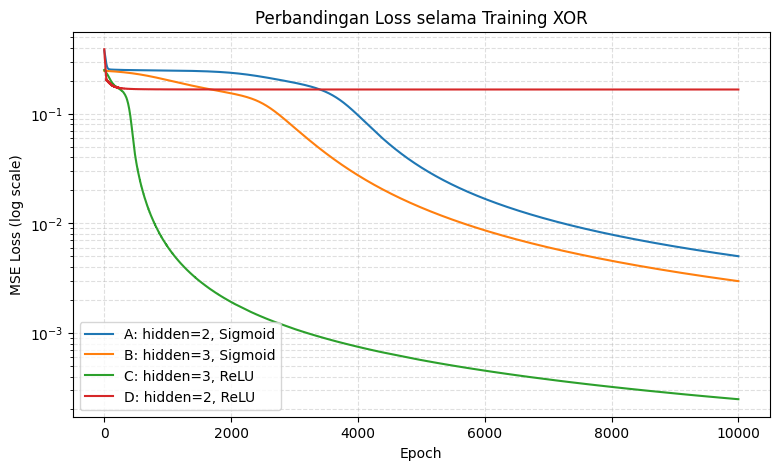

In [7]:
plt.figure(figsize=(9, 5))

for name in results:
    plt.plot(results[name]['loss_history'], label=name)

plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss (log scale)')
plt.title('Perbandingan Loss selama Training XOR')
plt.legend()
plt.grid(True, which='both', ls='--', alpha=0.4)
plt.show()

## 8. Analisis Hasil

Seluruh angka pada bagian ini diambil dari output aktual notebook.

| Konfigurasi | Hidden | Aktivasi | Final Loss | Prediksi | XOR benar? |
|---|---|---:|---|---|---|
| A | 2 | Sigmoid | 0.005012 | [0.069, 0.923, 0.925, 0.062] | Ya |
| B | 3 | Sigmoid | 0.002968 | [0.041, 0.929, 0.962, 0.062] | Ya |
| C | 3 | ReLU | 0.000248 | [0.020, 0.990, 0.990, 0.020] | Ya |
| D | 2 | ReLU | 0.166694 | [0.667, 0.667, 0.667, 0.010] | Tidak |

1. **Baseline berhasil mempelajari XOR.** Dengan 2 neuron hidden dan Sigmoid, loss turun ke 0.005012 dan prediksi mendekati target 0, 1, 1, 0.
2. **Menambah neuron hidden menjadi 3 memperbaiki loss.** Loss Sigmoid turun dari 0.005012 menjadi 0.002968, sekitar 41% lebih rendah, dengan prediksi yang tetap benar.
3. **ReLU dengan 3 neuron hidden memberikan loss terbaik.** Nilainya 0.000248, sekitar 95% lebih rendah daripada baseline Sigmoid, dan prediksi hampir tepat 0 atau 1.
4. **ReLU dengan 2 neuron hidden gagal.** Ketiga prediksi pertama bernilai sekitar 0.667 dan prediksi terakhir 0.010, sehingga pola XOR tidak terbentuk. Dengan hanya 2 unit ReLU, kapasitas model tidak cukup untuk membentuk dua daerah keputusan XOR pada inisialisasi ini.
5. **Kesimpulan.** Menambah neuron membantu menurunkan loss, dan ReLU efektif jika kapasitas hidden layer mencukupi. ReLU pada hidden layer yang terlalu kecil justru tidak konvergen.
6. **Catatan.** Loss adalah MSE pada 4 data XOR dan hanya memakai satu seed. Inisialisasi berbeda dapat mengubah hasil, terutama pada konfigurasi D yang gagal.